In [1]:
"""
UNIZAR ML PROJECT RUNPOD.ipynb
==============
LoRA finetuning of Flan-T5 base on merged MBPP + SPIDER data.
No local project imports — all helpers are defined inline.

Copy each CELL block into a separate code cell in your Colab notebook.

CELL 1 — Install dependencies
CELL 2 — Configuration & Google Drive setup
CELL 3 — Helper functions (JSONL reader, dataset class, compute_metrics)
CELL 4 — Load & merge MBPP + SPIDER data, build train/eval splits
CELL 5 — Load fp32 model & tokenizer, apply LoRA, inspect trainable params
CELL 6 — Sanity check: inspect a sample batch
CELL 7 — Configure training args, run Trainer, save adapter weights
CELL 8 — Merge adapter → full model, plot loss curve, final summary

Strategy : Standard LoRA — fp32 base model + LoRA adapters (no quantization)
Model    : google/flan-t5-base (250M params, ~1 GB in fp32)
VRAM     : ~3–4 GB with gradient checkpointing (T4 compatible)
Epochs   : 5
"""

'\nUNIZAR ML PROJECT RUNPOD.ipynb\n==============\nLoRA finetuning of Flan-T5 base on merged MBPP + SPIDER data.\nNo local project imports — all helpers are defined inline.\n\nCopy each CELL block into a separate code cell in your Colab notebook.\n\nCELL 1 — Install dependencies\nCELL 2 — Configuration & Google Drive setup\nCELL 3 — Helper functions (JSONL reader, dataset class, compute_metrics)\nCELL 4 — Load & merge MBPP + SPIDER data, build train/eval splits\nCELL 5 — Load fp32 model & tokenizer, apply LoRA, inspect trainable params\nCELL 6 — Sanity check: inspect a sample batch\nCELL 7 — Configure training args, run Trainer, save adapter weights\nCELL 8 — Merge adapter → full model, plot loss curve, final summary\n\nStrategy : Standard LoRA — fp32 base model + LoRA adapters (no quantization)\nModel    : google/flan-t5-base (250M params, ~1 GB in fp32)\nVRAM     : ~3–4 GB with gradient checkpointing (T4 compatible)\nEpochs   : 5\n'

In [2]:
# =============================================================================
# CELL 1 — Install Dependencies
# =============================================================================
!pip install -q --upgrade typing_extensions
!pip install -q datasets transformers sentencepiece evaluate rouge-score \
             accelerate peft bitsandbytes tqdm wandb matplotlib
print("✓ All dependencies installed")


[notice] A new release of pip is available: 24.2 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip
✓ All dependencies installed


In [3]:
# =============================================================================
# CELL 2 — Configuration & RunPod Setup
# =============================================================================

import os
import json
import math
import random
from pathlib import Path
from datetime import datetime

import torch
import numpy as np

# ── W&B login — reads WANDB_API_KEY env var set in RunPod's Secrets panel ─────
import wandb
wandb_api_key = os.environ.get("WANDB_API_KEY", None)
wandb.login(key=wandb_api_key)   # key=None falls back to interactive prompt

# ── Project root — RunPod persistent storage lives at /workspace ───────────────
# /workspace persists across pod restarts. /tmp and /root do NOT.
PROJECT_ROOT = Path("/workspace/FlanT5_Finetune")

# ── Data paths (must exist after running preprocess_data.py) ──────────────────
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MBPP_TRAIN    = PROCESSED_DIR / "mbpp_train.jsonl"
SPIDER_TRAIN  = PROCESSED_DIR / "spider_train.jsonl"

# ── Output paths ──────────────────────────────────────────────────────────────
RESULTS_DIR    = PROJECT_ROOT / "results" / "finetuned_lora"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
ADAPTER_DIR    = RESULTS_DIR / "adapter"    # lightweight LoRA adapter (~7 MB, 1.77M params × fp32)
MERGED_DIR     = RESULTS_DIR / "merged"     # full merged model for evaluation

for d in [RESULTS_DIR, CHECKPOINT_DIR, ADAPTER_DIR, MERGED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Model ─────────────────────────────────────────────────────────────────────
MODEL_NAME = "google/flan-t5-base"

# ── Sequence lengths ──────────────────────────────────────────────────────────
# 512 input covers >95% of MBPP + SPIDER examples (verified in preprocess stats)
# 256 output is more than enough for Python functions and SQL queries
MAX_INPUT_LENGTH  = 512
MAX_TARGET_LENGTH = 256

# ── Data split ────────────────────────────────────────────────────────────────
# 10% of the merged training data is held out for in-training monitoring.
# This is separate from the test splits used for final evaluation.
EVAL_SPLIT = 0.10
SEED       = 42

# ── Training hyperparameters ──────────────────────────────────────────────────
# RunPod GPU tuning guide — adjust BATCH_SIZE, GRAD_ACCUM, and precision:
#   RTX 3090 (24 GB) : BATCH_SIZE=8,  GRAD_ACCUM=4, fp16=True
#   A40      (48 GB) : BATCH_SIZE=16, GRAD_ACCUM=2, fp16=True
#   A100     (80 GB) : BATCH_SIZE=32, GRAD_ACCUM=1, bf16=True  (fastest option)
NUM_EPOCHS    = 5
BATCH_SIZE    = 8           # per-device; see GPU tuning guide above
GRAD_ACCUM    = 4           # effective batch = BATCH_SIZE × GRAD_ACCUM = 32
LEARNING_RATE = 3e-4        # standard LoRA learning rate for seq2seq
WARMUP_RATIO  = 0.05        # 5% linear warmup avoids early gradient spikes

# ── LoRA hyperparameters ──────────────────────────────────────────────────────
# rank=16, alpha=32  →  scaling factor = alpha/r = 2.0  (a widely-used default)
# target_modules: Flan-T5 uses "q", "k", "v", "o" (not "q_proj" like LLaMA)
# Adding all four projections gives slightly better coverage than q+v alone,
# but q+v is sufficient for most tasks. Adjust if needed.
LORA_R        = 16
LORA_ALPHA    = 32
LORA_DROPOUT  = 0.05        # light dropout; higher values hurt short sequences
LORA_TARGETS  = ["q", "v"] # encoder + decoder self-attention & cross-attention

# ── W&B ───────────────────────────────────────────────────────────────────────
WANDB_PROJECT  = "flan-t5-code-generation"
timestamp      = datetime.now().strftime("%Y%m%d_%H%M")
WANDB_RUN_NAME = f"flan-t5-lora-r{LORA_R}-mbpp-spider-{timestamp}"

print(f"✓ Project root      : {PROJECT_ROOT}")
print(f"✓ CUDA available    : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU               : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM              : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"✓ W&B project       : {WANDB_PROJECT}")
print(f"✓ Run name          : {WANDB_RUN_NAME}")
print(f"✓ Adapter save path : {ADAPTER_DIR}")
print(f"✓ Merged save path  : {MERGED_DIR}")
print(f"✓ Effective batch   : {BATCH_SIZE * GRAD_ACCUM}")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: azamafridi987 (azamafridi987-student) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


✓ Project root      : /workspace/FlanT5_Finetune
✓ CUDA available    : True
  GPU               : NVIDIA GeForce RTX 3090
  VRAM              : 25.3 GB
✓ W&B project       : flan-t5-code-generation
✓ Run name          : flan-t5-lora-r16-mbpp-spider-20260412_1339
✓ Adapter save path : /workspace/FlanT5_Finetune/results/finetuned_lora/adapter
✓ Merged save path  : /workspace/FlanT5_Finetune/results/finetuned_lora/merged
✓ Effective batch   : 32


In [4]:
# =============================================================================
# CELL 3 — Helper Functions
# =============================================================================

from torch.utils.data import Dataset
import evaluate as hf_evaluate

# ── JSONL reader ──────────────────────────────────────────────────────────────
def read_jsonl(path):
    """Read a JSONL file into a list of dicts. Skips blank lines."""
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def normalize_sql(sql):
    sql = sql.replace("<=", " LESS_EQUAL ")
    sql = sql.replace(">=", " GREATER_EQUAL ")
    sql = sql.replace("<", " LESS ")
    sql = sql.replace(">", " GREATER ")
    return sql

# ── PyTorch Dataset ───────────────────────────────────────────────────────────
class Seq2SeqCodeDataset(Dataset):
    """
    Tokenized seq2seq dataset wrapping a list of {input, output} dicts.

    Design notes:
      - Padding is applied here (padding="max_length") so that the default
        DataCollatorWithPadding is not needed; Seq2SeqTrainer works with
        collate_fn=None fine when tensors are already fixed-length.
      - Labels are masked at pad positions with -100 so the cross-entropy
        loss ignores padding tokens.
      - text_target= is used for the decoder side (modern HuggingFace API).
    """

    def __init__(
        self,
        examples: list,
        tokenizer,
        max_input_length:  int = 512,
        max_target_length: int = 256,
    ):
        self.examples          = examples
        self.tokenizer         = tokenizer
        self.max_input_length  = max_input_length
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        ex = self.examples[idx]

        # ── Encoder side ──────────────────────────────────────────────────────
        enc = self.tokenizer(
            ex["input"],
            max_length=self.max_input_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        # ── Decoder side (targets) ────────────────────────────────────────────
        # text_target= invokes the decoder tokenizer, which for T5 adds the
        # correct decoder_start_token_id automatically.
        dec = self.tokenizer(
            text_target=ex["output"],
            max_length=self.max_target_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        # Replace pad token id with -100 so loss ignores padding
        label_ids = dec["input_ids"].squeeze().clone()
        label_ids[label_ids == self.tokenizer.pad_token_id] = -100

        return {
            "input_ids":      enc["input_ids"].squeeze(),        # (seq_len,)
            "attention_mask": enc["attention_mask"].squeeze(),   # (seq_len,)
            "labels":         label_ids,                         # (tgt_len,)
        }


# ── compute_metrics (ROUGE-1 & ROUGE-L for in-training monitoring) ────────────
# NOTE: these are proxy metrics only. Final evaluation uses:
#   • MBPP   → pass@1 (execution-based)
#   • SPIDER → Exact Set Match (normalised SQL comparison)
rouge_metric = hf_evaluate.load("rouge")

def make_compute_metrics(tok):
    """Return a compute_metrics function bound to the given tokenizer."""
    def compute_metrics(eval_preds):
        predictions, labels = eval_preds
        if isinstance(predictions, tuple):
            predictions = predictions[0]

        # Clip to valid vocab range before decoding (avoids index errors)
        predictions = np.clip(predictions, 0, tok.vocab_size - 1)

        # Restore -100 masked positions to pad_token_id before decoding
        labels = np.where(labels != -100, labels, tok.pad_token_id)

        decoded_preds  = tok.batch_decode(predictions, skip_special_tokens=True)
        decoded_labels = tok.batch_decode(labels,      skip_special_tokens=True)

        decoded_preds  = [p.strip() for p in decoded_preds]
        decoded_labels = [l.strip() for l in decoded_labels]

        result = rouge_metric.compute(
            predictions=decoded_preds,
            references=decoded_labels,
        )
        return {
            "rouge1": round(result["rouge1"], 4),
            "rougeL": round(result["rougeL"], 4),
        }
    return compute_metrics


print("✓ Helper functions defined")

✓ Helper functions defined


In [5]:
# =============================================================================
# CELL 4 — Load & Merge Data, Build Train/Eval Splits
# =============================================================================

# ── Load processed JSONL files from Drive ────────────────────────────────────
print("Loading MBPP training data...")
mbpp_examples = read_jsonl(MBPP_TRAIN)
print(f"  ✓ {len(mbpp_examples):,} MBPP examples")

print("\nLoading SPIDER training data...")
spider_examples = read_jsonl(SPIDER_TRAIN)
print(f"  ✓ {len(spider_examples):,} SPIDER examples")

# Normalize SQL outputs (VERY IMPORTANT FIX)
for ex in spider_examples:
    ex["output"] = normalize_sql(ex["output"])

# ── Merge and shuffle ─────────────────────────────────────────────────────────
all_examples = mbpp_examples + spider_examples
rng = random.Random(SEED)
rng.shuffle(all_examples)

# ── 90 / 10 train / eval split ───────────────────────────────────────────────
# The 10% eval split is drawn from the *training* data and used only for
# loss monitoring during training. The held-out test splits from
# preprocess_data.py (mbpp_test.jsonl, spider_test.jsonl) are used for
# final pass@1 and Exact Set Match evaluation.
split_idx      = int(len(all_examples) * (1 - EVAL_SPLIT))
train_examples = all_examples[:split_idx]
eval_examples  = all_examples[split_idx:]

# ── Per-task breakdown ────────────────────────────────────────────────────────
def count_by_task(examples):
    mbpp   = sum(1 for ex in examples if "Generate Python:"  in ex["input"])
    spider = sum(1 for ex in examples if "Translate to SQL:" in ex["input"])
    return mbpp, spider

tr_mbpp, tr_spider = count_by_task(train_examples)
ev_mbpp, ev_spider = count_by_task(eval_examples)

print(f"\nDataset split (seed={SEED}, eval={EVAL_SPLIT:.0%}):")
print(f"  Train : {len(train_examples):,} total  ({tr_mbpp:,} MBPP + {tr_spider:,} SPIDER)")
print(f"  Eval  : {len(eval_examples):,} total  ({ev_mbpp:,} MBPP + {ev_spider:,} SPIDER)")

# ── Preview one sample of each task type ─────────────────────────────────────
print("\nSample [MBPP] input prompt:")
print(next(ex for ex in train_examples if "Generate Python:" in ex["input"])["input"][:300])

print("\nSample [SPIDER] input prompt:")
print(next(ex for ex in train_examples if "Translate to SQL:" in ex["input"])["input"][:300])

Loading MBPP training data...
  ✓ 464 MBPP examples

Loading SPIDER training data...
  ✓ 7,000 SPIDER examples

Dataset split (seed=42, eval=10%):
  Train : 6,717 total  (421 MBPP + 6,296 SPIDER)
  Eval  : 747 total  (43 MBPP + 704 SPIDER)

Sample [MBPP] input prompt:
Generate Python: Write a function that matches a string that has an 'a' followed by anything, ending in 'b' by using regex.
Test cases:
assert text_match("aabbbbd") == 'Not matched!'
assert text_match("aabAbbbc") == 'Not matched!'
assert text_match("accddbbjjjb") == 'Found a match!'

Sample [SPIDER] input prompt:
Translate to SQL: What are the different names of friends who are younger than the average age for a friend?
Database schema:
Person: name (text), age (number), city (text), gender (text), job (text) | PersonFriend: name (text), friend (text), year (number)


In [6]:

# =============================================================================
# CELL 5 — Load Model & Tokenizer, Apply LoRA
# =============================================================================

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

# ── Tokenizer ─────────────────────────────────────────────────────────────────
print(f"Loading tokenizer ({MODEL_NAME})...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ── Base model in fp32 ────────────────────────────────────────────────────────
# Loaded in full 32-bit precision for numerical stability.
# fp16 was tested and caused NaN losses during the backward pass on T4;
# fp32 uses more VRAM (~1 GB) but backpropagation is completely stable.
# No bitsandbytes quantization is used.
print(f"\nLoading {MODEL_NAME} in fp32...")
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,   # fp32 — stable backprop on T4
    device_map="auto",
)
print("✓ Base model loaded in fp32")

# Disable KV-cache during training — required when gradient_checkpointing=True.
# T5 caches key-value pairs by default for faster autoregressive generation,
# but this conflicts with gradient checkpointing in the backward pass and
# can cause NaN activations in the decoder cross-attention.
model.config.use_cache = False

# ── LoRA configuration ────────────────────────────────────────────────────────
# task_type=SEQ_2_SEQ_LM wraps the encoder-decoder T5 architecture correctly.
# target_modules: Flan-T5 attention projection names are "q", "k", "v", "o"
# (not "q_proj" / "v_proj" as in decoder-only LLaMA-family models).
lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    target_modules=LORA_TARGETS,    # ["q", "v"]
    lora_dropout=LORA_DROPOUT,
    bias="none",                    # don't train biases (keeps adapter small)
)
model = get_peft_model(model, lora_config)

# ── Print trainable parameter summary ────────────────────────────────────────
print("\n── Trainable parameters ──────────────────────────────────────────────")
model.print_trainable_parameters()   # expect ~3.5M / 250M (~1.4%)
print("─────────────────────────────────────────────────────────────────────")

# ── Build tokenized PyTorch datasets ─────────────────────────────────────────
train_dataset = Seq2SeqCodeDataset(
    train_examples, tokenizer, MAX_INPUT_LENGTH, MAX_TARGET_LENGTH
)
eval_dataset = Seq2SeqCodeDataset(
    eval_examples, tokenizer, MAX_INPUT_LENGTH, MAX_TARGET_LENGTH
)
print(f"\n✓ Train dataset : {len(train_dataset):,} examples")
print(f"✓ Eval dataset  : {len(eval_dataset):,} examples")

Loading tokenizer (google/flan-t5-base)...


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✓ Base model loaded in fp32

── Trainable parameters ──────────────────────────────────────────────
trainable params: 1,769,472 || all params: 249,347,328 || trainable%: 0.7096
─────────────────────────────────────────────────────────────────────

✓ Train dataset : 6,717 examples
✓ Eval dataset  : 747 examples


In [7]:
# =============================================================================
# CELL 6 — Sanity Check: Inspect a Sample Batch
# =============================================================================
# Verifies that input_ids, attention_mask, and labels are correctly tokenized
# before launching training. Run this cell and inspect the decoded text to
# confirm the prompt format and label masking look correct.

sample = train_dataset[0]

print("── Sample 0 ──────────────────────────────────────────────────────────")
print("Input (decoded):")
print(tokenizer.decode(sample["input_ids"], skip_special_tokens=True))

print("\nLabels (raw tensor, first 20 tokens):")
print(sample["labels"][:20].tolist())

print("\nTarget (decoded, -100 positions excluded):")
valid_label_ids = sample["labels"][sample["labels"] != -100]
print(tokenizer.decode(valid_label_ids, skip_special_tokens=True))

print("\n── First 5 training examples (decoded targets) ──────────────────────")
for i in range(5):
    s = train_dataset[i]
    valid = s["labels"][s["labels"] != -100]
    task  = "MBPP  " if "Generate Python:" in train_examples[i]["input"] else "SPIDER"
    print(f"  [{task}] {tokenizer.decode(valid, skip_special_tokens=True)[:120]}")

print("\n✓ Dataset looks correct — proceed to training")

── Sample 0 ──────────────────────────────────────────────────────────
Input (decoded):
Translate to SQL: What are the different names of friends who are younger than the average age for a friend? Database schema: Person: name (text), age (number), city (text), gender (text), job (text) | PersonFriend: name (text), friend (text), year (number)

Labels (raw tensor, first 20 tokens):
[3, 23143, 14196, 3, 15438, 25424, 6227, 332, 4416, 4350, 21680, 5780, 6157, 332, 536, 3, 15355, 3162, 5780, 17701]

Target (decoded, -100 positions excluded):
SELECT DISTINCT T2.name FROM Person AS T1 JOIN PersonFriend AS T2 ON T1.name = T2.friend WHERE T1.age LESS (SELECT avg(age) FROM person)

── First 5 training examples (decoded targets) ──────────────────────
  [SPIDER] SELECT DISTINCT T2.name FROM Person AS T1 JOIN PersonFriend AS T2 ON T1.name = T2.friend WHERE T1.age LESS (SELECT avg(a
  [SPIDER] SELECT DISTINCT t3.policy_type_code FROM customers AS t1 JOIN customers_policies AS t2 ON t1.customer_id

In [ ]:
# # =============================================================================
# # CELL X — Debugging Cell
# # =============================================================================

# import torch

# batch = next(iter(trainer.get_train_dataloader()))
# batch = {k: v.to(model.device) for k, v in batch.items()}

# with torch.no_grad():
#     outputs = model(**batch)

# print(f"Loss value : {outputs.loss}")
# print(f"Is NaN     : {torch.isnan(outputs.loss)}")
# print(f"Is Inf     : {torch.isinf(outputs.loss)}")
# print(f"Logits NaN : {torch.isnan(outputs.logits).any()}")

In [ ]:
# # =============================================================================
# # CELL X — Debugging Cell
# # =============================================================================

# # Cast to fp32 for the forward pass and check again
# with torch.no_grad():
#     model_fp32 = model.float()   # temporarily cast to fp32
#     batch_fp32 = {k: v.float() if v.is_floating_point() else v for k, v in batch.items()}
#     outputs_fp32 = model_fp32(**batch_fp32)

# print(f"fp32 loss  : {outputs_fp32.loss}")
# print(f"fp32 NaN   : {torch.isnan(outputs_fp32.loss)}")

In [ ]:
# # =============================================================================
# # CELL X — Debugging Cell
# # =============================================================================


# # Run ONE manual forward + backward and inspect gradients
# model.train()
# batch = next(iter(trainer.get_train_dataloader()))
# batch = {k: v.to(model.device) for k, v in batch.items()}

# outputs = model(**batch)
# outputs.loss.backward()

# # Check gradients on the LoRA parameters only
# grad_norms = []
# for name, param in model.named_parameters():
#     if param.requires_grad and param.grad is not None:
#         grad_norms.append((name, param.grad.norm().item()))

# print(f"Loss                  : {outputs.loss.item():.4f}")
# print(f"Trainable params with grad : {len(grad_norms)}")
# print(f"Any NaN grads         : {any(torch.isnan(p.grad).any() for _, p in model.named_parameters() if p.requires_grad and p.grad is not None)}")
# print(f"Any Inf grads         : {any(torch.isinf(p.grad).any() for _, p in model.named_parameters() if p.requires_grad and p.grad is not None)}")
# print(f"\nSample grad norms (first 5 LoRA params):")
# for name, norm in grad_norms[:5]:
#     print(f"  {name[-50:]:>50} | grad norm = {norm:.6f}")

In [8]:
# =============================================================================
# CELL 7 — Configure Training Arguments & Run Trainer
# =============================================================================

from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer
from torch.utils.data import Subset

# ── Initialize W&B run explicitly (gives you the dashboard URL early) ─────────
wandb_run = wandb.init(
    project=WANDB_PROJECT,
    name=WANDB_RUN_NAME,
    config={
        "model":             MODEL_NAME,
        "strategy":          "LoRA (fp16, no quantization)",
        "lora_r":            LORA_R,
        "lora_alpha":        LORA_ALPHA,
        "lora_dropout":      LORA_DROPOUT,
        "target_modules":    LORA_TARGETS,
        "epochs":            NUM_EPOCHS,
        "batch_size":        BATCH_SIZE,
        "grad_accum":        GRAD_ACCUM,
        "effective_batch":   BATCH_SIZE * GRAD_ACCUM,
        "learning_rate":     LEARNING_RATE,
        "warmup_ratio":      WARMUP_RATIO,
        "max_input_length":  MAX_INPUT_LENGTH,
        "max_target_length": MAX_TARGET_LENGTH,
        "train_examples":    len(train_dataset),
        "eval_examples":     len(eval_dataset),
        "seed":              SEED,
    },
)
print(f"✓ W&B run: {wandb_run.url}")

# ── Training arguments ────────────────────────────────────────────────────────
training_args = Seq2SeqTrainingArguments(
    output_dir=str(CHECKPOINT_DIR),

    # ── Epochs & batch ────────────────────────────────────────────────────────
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,

    # ── Optimizer & scheduler ─────────────────────────────────────────────────
    learning_rate=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="linear",
    max_grad_norm=1.0,          # standard gradient clipping — prevents large updates from noisy batches
    fp16=False,   # disabled — backward pass was overflowing
    bf16=False,   # T4 doesn't support this anyway

    # ── Memory optimisation ───────────────────────────────────────────────────
    # gradient_checkpointing trades compute for memory: recomputes activations
    # during the backward pass instead of storing them all.
    # use_reentrant=False avoids a known PyTorch autograd incompatibility with
    # non-reentrant checkpointing in seq2seq models.
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},

    # ── Generation (for predict_with_generate / compute_metrics) ─────────────
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,

    # ── Evaluation & checkpointing ────────────────────────────────────────────
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,             # keep the 3 most recent checkpoints
    load_best_model_at_end=False,   # reloading a PEFT model from checkpoint
                                    # is unreliable; identify the best epoch
                                    # from the W&B dashboard instead

    # ── Logging ───────────────────────────────────────────────────────────────
    logging_steps=1,                # log every optimizer step (important for small subset runs)
    report_to="wandb",
    run_name=WANDB_RUN_NAME,

    # ── Reproducibility ───────────────────────────────────────────────────────
    seed=SEED,
)

# ── Trainer ───────────────────────────────────────────────────────────────────
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,         # replaces deprecated tokenizer= kwarg
    compute_metrics=make_compute_metrics(tokenizer),
)

# ── Pre-flight summary ────────────────────────────────────────────────────────
opt_steps = math.ceil(len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM)) * NUM_EPOCHS

print(f"\n🚀 Starting LoRA training...")
print(f"   Model          : {MODEL_NAME} (fp16, no quantization)")
print(f"   LoRA rank      : {LORA_R}  |  alpha = {LORA_ALPHA}")
print(f"   Epochs         : {NUM_EPOCHS}")
print(f"   Train examples : {len(train_dataset):,}")
print(f"   Eval  examples : {len(eval_dataset):,}")
print(f"   Effective batch: {BATCH_SIZE * GRAD_ACCUM}")
print(f"   Optimizer steps: {opt_steps:,}")
print(f"   W&B dashboard  : {wandb_run.url}\n")

trainer.train()

print("\n✓ Training complete!")

# ── Save LoRA adapter weights ─────────────────────────────────────────────────
# Only the LoRA delta weights are saved (~14 MB), not the full model.
# The adapter can be re-loaded with PeftModel.from_pretrained() for inference.
model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))
print(f"✓ Adapter weights saved → {ADAPTER_DIR}")
print(f"  Tip: check the W&B dashboard for the epoch with lowest eval_loss,")
print(f"       then load that adapter from: {CHECKPOINT_DIR}")

print("\n── Raw log history (loss column) ──")
for entry in trainer.state.log_history:
    if "loss" in entry and "eval_loss" not in entry:
        print(f"  step {entry['step']:>4} | loss = {entry['loss']}")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


✓ W&B run: https://wandb.ai/azamafridi987-student/flan-t5-code-generation/runs/ar51961y

🚀 Starting LoRA training...
   Model          : google/flan-t5-base (fp16, no quantization)
   LoRA rank      : 16  |  alpha = 32
   Epochs         : 5
   Train examples : 6,717
   Eval  examples : 747
   Effective batch: 32
   Optimizer steps: 1,050
   W&B dashboard  : https://wandb.ai/azamafridi987-student/flan-t5-code-generation/runs/ar51961y



/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]


Epoch,Training Loss,Validation Loss,Rouge1,Rougel
1,3.354561,0.497826,0.604800,0.580600
2,2.138553,0.417660,0.676600,0.653000
3,3.196043,0.384208,0.690500,0.668000
4,1.986030,0.366816,0.710000,0.688300
5,2.007106,0.362051,0.711200,0.689100


/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/utils/checkpoint.py:1399: FutureWarning: `torch.cpu.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cpu', args...)` instead.
  with device_autocast_ctx, torch.cpu.amp.autocast(**cpu_autocast_kwargs), recompute_context:  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/uti


✓ Training complete!
✓ Adapter weights saved → /workspace/FlanT5_Finetune/results/finetuned_lora/adapter
  Tip: check the W&B dashboard for the epoch with lowest eval_loss,
       then load that adapter from: /workspace/FlanT5_Finetune/results/finetuned_lora/checkpoints

── Raw log history (loss column) ──
  step    1 | loss = 9.490602493286133
  step    2 | loss = 10.214262008666992
  step    3 | loss = 11.317106246948242
  step    4 | loss = 9.697049140930176
  step    5 | loss = 10.49296760559082
  step    6 | loss = 10.951919555664062
  step    7 | loss = 9.457613945007324
  step    8 | loss = 9.172969818115234
  step    9 | loss = 10.200690269470215
  step   10 | loss = 9.839122772216797
  step   11 | loss = 8.828116416931152
  step   12 | loss = 9.59847640991211
  step   13 | loss = 9.89530086517334
  step   14 | loss = 9.655899047851562
  step   15 | loss = 8.851869583129883
  step   16 | loss = 10.499018669128418
  step   17 | loss = 8.915639877319336
  step   18 | loss = 10.2

Merging LoRA adapter into base model...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Merged model saved → /workspace/FlanT5_Finetune/results/finetuned_lora/merged


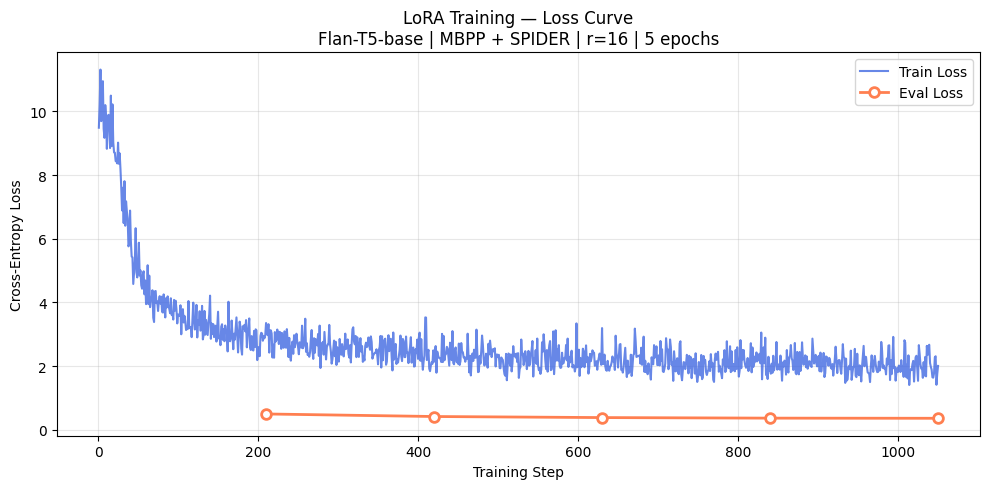

✓ Loss curve saved → /workspace/FlanT5_Finetune/results/finetuned_lora/lora_loss_curve.png


eval/loss,█▄▂▁▁
eval/rouge1,▁▆▇██
eval/rougeL,▁▆▇██
eval/runtime,█▁▄▁▂
eval/samples_per_second,▁█▄█▇
eval/steps_per_second,▁█▄█▇
train/epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇████
train/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇███
train/grad_norm,▃▇▆█▇▃▂▃▅▁▂▄▃▃▂█▂▂▃▂▃▁▃▃▄▃▃▄▆▄▂▄▂▄▅▅▃▅▃▄
train/learning_rate,▂▂▅▇▇████▇▇▇▇▇▇▆▆▆▆▆▆▅▅▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▁
+1,...



✅ LoRA Finetuning Complete!
   Adapter weights  : /workspace/FlanT5_Finetune/results/finetuned_lora/adapter
   Merged model     : /workspace/FlanT5_Finetune/results/finetuned_lora/merged
   Loss curve       : /workspace/FlanT5_Finetune/results/finetuned_lora/lora_loss_curve.png
   W&B run          : https://wandb.ai/azamafridi987-student/flan-t5-code-generation/runs/ar51961y
   → Load merged model in evaluation notebooks
     for pass@1 (MBPP) and Exact Set Match (SPIDER)


In [9]:
# =============================================================================
# CELL 8 — Merge Adapter → Full Model, Plot Loss Curve, Final Summary
# =============================================================================

import matplotlib.pyplot as plt

# ── Merge LoRA into base model ────────────────────────────────────────────────
# merge_and_unload() adds the LoRA delta weights directly into the base model
# parameters and returns a standard HuggingFace AutoModelForSeq2SeqLM.
# The merged model is needed by the evaluation notebooks (no PEFT dependency).
print("Merging LoRA adapter into base model...")
merged_model = model.merge_and_unload()
merged_model.save_pretrained(str(MERGED_DIR))
tokenizer.save_pretrained(str(MERGED_DIR))
print(f"✓ Merged model saved → {MERGED_DIR}")

# ── Plot training & eval loss ─────────────────────────────────────────────────
log_history  = trainer.state.log_history

train_steps  = [e["step"]      for e in log_history if "loss"      in e and "eval_loss" not in e]
train_losses = [e["loss"]      for e in log_history if "loss"      in e and "eval_loss" not in e]
eval_steps   = [e["step"]      for e in log_history if "eval_loss" in e]
eval_losses  = [e["eval_loss"] for e in log_history if "eval_loss" in e]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    train_steps, train_losses,
    label="Train Loss", color="royalblue", linewidth=1.5, alpha=0.8,
)
ax.plot(
    eval_steps, eval_losses,
    label="Eval Loss",  color="coral",     linewidth=2,
    marker="o", markersize=7, markerfacecolor="white", markeredgewidth=2,
)
ax.set_xlabel("Training Step")
ax.set_ylabel("Cross-Entropy Loss")
ax.set_title(
    f"LoRA Training — Loss Curve\n"
    f"Flan-T5-base | MBPP + SPIDER | r={LORA_R} | {NUM_EPOCHS} epochs"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

curve_path = RESULTS_DIR / "lora_loss_curve.png"
plt.savefig(str(curve_path), dpi=150)
plt.show()
print(f"✓ Loss curve saved → {curve_path}")

# ── Finish W&B run ────────────────────────────────────────────────────────────
wandb.finish()

# ── Final summary ─────────────────────────────────────────────────────────────
print("\n" + "=" * 62)
print("✅ LoRA Finetuning Complete!")
print(f"   Adapter weights  : {ADAPTER_DIR}")
print(f"   Merged model     : {MERGED_DIR}")
print(f"   Loss curve       : {curve_path}")
print(f"   W&B run          : {wandb_run.url}")
print("   → Load merged model in evaluation notebooks")
print("     for pass@1 (MBPP) and Exact Set Match (SPIDER)")
print("=" * 62)